# Read and filter WildChat 1M

- Dataset - https://huggingface.co/datasets/allenai/WildChat-1M/tree/main/data
- Website - https://wildchat.allen.ai/
- Paper - https://arxiv.org/abs/2405.01470

In [1]:
import pandas as pd

In [2]:
dfs = []

for i in range(14):
    
    dfs.append(
        pd.read_parquet(f'wildchat-1m/train-000{i:02d}-of-00014.parquet')
            .query('language == "English"')
    )

data_en = pd.concat(dfs)

count    478498.000000
mean       2117.675039
std        7744.765335
min           0.000000
25%          90.000000
50%         407.000000
75%        3727.000000
max      597942.000000
Name: first_turn_len, dtype: float64

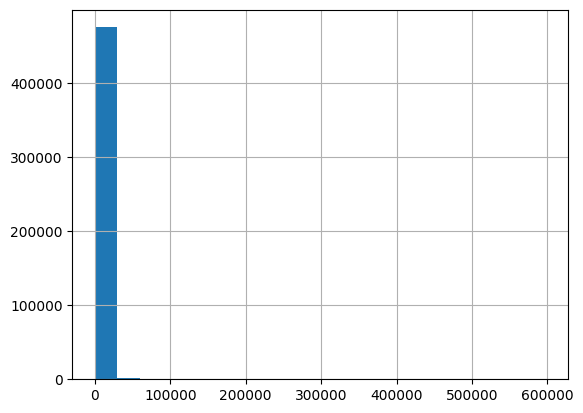

In [3]:
data = data_en.assign(
    first_turn=lambda df_: df_.conversation.apply(lambda x: x[0]['content'].strip()),
    first_turn_len=lambda df_: df_.first_turn.str.len()
)

data.first_turn_len.hist(bins=20)
data.first_turn_len.describe()

In [7]:
data.timestamp.sort_values()

0       2023-04-09 00:02:53+00:00
2       2023-04-09 00:04:52+00:00
4       2023-04-09 00:06:49+00:00
7       2023-04-09 00:08:41+00:00
8       2023-04-09 00:10:00+00:00
                   ...           
59849   2024-04-29 23:52:33+00:00
59851   2024-04-29 23:55:00+00:00
59852   2024-04-29 23:55:11+00:00
59853   2024-04-29 23:55:24+00:00
59854   2024-04-29 23:56:30+00:00
Name: timestamp, Length: 478498, dtype: datetime64[us, UTC]

In [13]:
data.first_turn_len.le(131).mean().round(3)

0.319

## For this study only, let's remove long first turns

- The idea is to use the same query classifier to identify geospatial intent/question that was trained on MS MARCO
- So we have to get turns that resemble search queries; in the MS MARCO Geospatial paper, 99.9% of queries are under 131 characters

In [6]:
print('Before removing long first turns:', data.shape[0])
data = data.query('first_turn_len <= 131')
print('After removing long first turns:', data.shape[0])

Before removing long first turns: 478498
After removing long first turns: 152724


In [7]:
data

,conversation_hash,model,timestamp,conversation,turn,language,openai_moderation,detoxify_moderation,toxic,redacted,state,country,hashed_ip,header,first_turn,first_turn_len
2,cf1267ca6b2f6fccc9c36652a00059a1,gpt-4-0314,2023-04-09 00:04:52+00:00,"[{'content': 'Old age PT hx of DM, HTN, dyslip...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0002258022577734664, 'i...",False,False,Mecca Region,Saudi Arabia,8133108d1c433c180c6be8302dc5a6681f2bec980190a1...,"{'accept-language': 'en-US,en;q=0.9', 'user-ag...","Old age PT hx of DM, HTN, dyslipidemia His ECG...",115
8,59c72510f3143025f94f75b883b026bd,gpt-3.5-turbo-0301,2023-04-09 00:10:00+00:00,[{'content': 'i wanna you to write me terms & ...,1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0007317529525607824, 'i...",False,False,Giza,Egypt,dbf18c49cf217bc344a40b187ed35c3219f994b1d3b2d0...,"{'accept-language': 'en-US,en;q=0.9', 'user-ag...",i wanna you to write me terms & conditions and...,71
18,aa7c3f49343e097be66442288abd1dac,gpt-4-0314,2023-04-09 00:23:46+00:00,"[{'content': 'Let A, B, and C be events with ...",7,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.00018260271463077515, '...",False,False,Alberta,Canada,e49e258fbabeb7e0916d44b43e30ad77e61026bd8cb07c...,"{'accept-language': 'en-US,en;q=0.9', 'user-ag...","Let A, B, and C be events with\n\nProb[A] = 0....",129
19,490344da63f175fb4628661808267ea8,gpt-3.5-turbo-0301,2023-04-09 00:24:45+00:00,[{'content': 'Give me free apps that create mi...,1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.00012093045370420441, '...",False,False,Bacău County,Romania,04bc40e4c20b71bd44d8263903d28d53138ba42673d2ac...,"{'accept-language': 'en-US,en;q=0.9,pa;q=0.8',...",Give me free apps that create midi files or sh...,67
23,576e59afd66835b3797517cd1cd8a08b,gpt-4-0314,2023-04-09 00:30:20+00:00,[{'content': 'how long does it take to orbit t...,3,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001060247013811022, 'i...",False,False,Florida,United States,09e0bc9c473bbbcb360a8ac668b2c90c8ee8b3fc34b6a3...,"{'accept-language': 'en-US,en;q=0.9', 'user-ag...",how long does it take to orbit the sun?,39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59832,7cb9e62786cd010639a9e3f5a2e9814e,gpt-4-0125-preview,2024-04-29 23:27:23+00:00,[{'content': 'explain: torch.manual_seed(1234)...,1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.00036763757816515863, '...",False,False,Oran,Algeria,0a8782e3888e933e1db7aa805ef066686f49c0d42fd8b0...,"{'accept-language': 'en-US,en;q=0.5', 'user-ag...",explain: torch.manual_seed(1234),32
59839,ea8a598338d5fe808f4f9a8c2bc587c3,gpt-3.5-turbo-0125,2024-04-29 23:36:38+00:00,"[{'content': 'Toy Story 5 plot:', 'country': '...",13,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0011648873332887888, 'i...",False,False,Ohio,United States,b6fd60e8ddc381203f341d08d73e5f3085eb1bc43ac86c...,"{'accept-language': 'en-GB,en-US;q=0.9,en;q=0....",Toy Story 5 plot:,17
59845,52b816a566e7a91d6c4e49d47632fd73,gpt-3.5-turbo-0125,2024-04-29 23:42:19+00:00,[{'content': '“Zee’s Bookshelf” from “Noggin” ...,5,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0002595778787508607, 'i...",False,False,Ohio,United States,b6fd60e8ddc381203f341d08d73e5f3085eb1bc43ac86c...,"{'accept-language': 'en-GB,en-US;q=0.9,en;q=0....",“Zee’s Bookshelf” from “Noggin” (2005),38
59848,02d847b3b5b21834bc04736eddcee2a1,gpt-3.5-turbo-0125,2024-04-29 23:49:02+00:00,[{'content': 'The plot of “The Upside Down Sho...,1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.00010419217142043635, '...",False,False,Ohio,United States,b6fd60e8ddc381203f341d08d73e5f3085eb1bc43ac86c...,"{'accept-language': 'en-GB,en-US;q=0.9,en;q=0....",The plot of 

## Remove duplicates

- Dataset is messy, so just look at country+first turn text 

In [9]:
print('Before deduplication:', data.shape[0])
data = data.drop_duplicates(subset=['first_turn', 'country'])
print('After deduplication:', data.shape[0])

Before deduplication: 152724
After deduplication: 133158


## What is conversation_hash and is it unique? Let's find out

- It looks like these are short conversations that are the same; example: `hi there', 'Hi there', etc

In [23]:
data.conversation_hash.value_counts()

conversation_hash
5e668a9490abfe0f46d38b76020f0eeb    12
cf369b693cfb3c0dd439b6c41dfea740    11
58a03dc3fdb0553a26ff45c37dd2333e    11
28003357c2221360a8dd0ff7b5f93b1c     9
58e762e4a8437c534079fa35371262db     7
                                    ..
3e0ab42b3f3e4b769d1133ff992bad06     1
8f5a5c1c748fc32187838e30f751bdb3     1
7c3d9dbabbce0151e6e1c15900a50f01     1
6a43c95f225022be89d49ea7dbddbfbf     1
ee21f5829cfe83c67c7b0d02da877a3e     1
Name: count, Length: 133076, dtype: int64

In [22]:
data[data.conversation_hash == "58a03dc3fdb0553a26ff45c37dd2333e"]

,conversation_hash,model,timestamp,conversation,turn,language,openai_moderation,detoxify_moderation,toxic,redacted,state,country,hashed_ip,header,first_turn,first_turn_len
31486,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0301,2023-04-23 19:55:04+00:00,"[{'content': 'Hi there', 'country': 'Vietnam',...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Da Nang,Vietnam,7e93b1f12d8912329bab0c44c9b8d626a9466942246038...,"{'accept-language': 'en,en-US;q=0.9,vi-VN;q=0....",Hi there,8
8105,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0301,2023-05-06 14:17:27+00:00,"[{'content': 'Hi there', 'country': 'Russia', ...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Lipetsk Oblast,Russia,01b5fd8017d809e134c1df6ac92a4f29e50e0c2723115f...,"{'accept-language': 'ru-RU,ru;q=0.9,en-us;q=0....",Hi there,8
13578,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0301,2023-06-10 12:30:00+00:00,"[{'content': 'Hi there', 'country': 'Kuwait', ...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Hawalli,Kuwait,fd97c2db548f31516e4fba050d7900afb3dd554d8d1da4...,"{'accept-language': 'en-GB,en-US;q=0.9,en;q=0....",Hi there,8
24691,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0301,2023-06-13 12:26:53+00:00,"[{'content': 'Hi there', 'country': 'Türkiye',...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Istanbul,Türkiye,d7d41d719c2f052ea6f72276ccf35790cecd43fa415aa0...,"{'accept-language': 'tr-TR,tr;q=0.9', 'user-ag...",Hi there,8
40686,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0613,2023-07-08 13:10:05+00:00,"[{'content': 'Hi there', 'country': 'Philippin...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Province of Batangas,Philippines,49351ad45ac46ed08854066367ffa984f9f48ba3622536...,"{'accept-language': 'en-US,en;q=0.9', 'user-ag...",Hi there,8
38291,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0613,2023-11-07 03:03:58+00:00,"[{'content': 'Hi there', 'country': 'Nepal', '...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Bagmati Province,Nepal,9f99d0bb098f9cd63b51f8832cbfe6a94d8510d000bbc1...,"{'accept-language': 'en-US,en;q=0.9', 'user-ag...",Hi there,8
39849,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0613,2023-11-07 16:58:44+00:00,"[{'content': 'Hi there', 'country': 'Israel', ...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,None,Israel,f46aaba051296621dd1f28f5503c99af2ab7d7d0a33abc...,"{'accept-language': 'he-IL,he;q=0.9,en-US;q=0....",Hi there,8
56171,58a03dc3fdb0553a26ff45c37dd2333e,gpt-4-1106-preview,2023-11-14 17:43:46+00:00,"[{'content': 'Hi there', 'country': 'Romania',...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Buzău County,Romania,39a1deec390847777a147c48db55478f7e7568615e08d9...,"{'accept-language': 'ro-RO,ro;q=0.6', 'user-ag...",Hi there,8
14921,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0613,2023-11-22 10:58:15+00:00,"[{'content': 'Hi there', 'country': 'Italy', '...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Province of Alessandria,Italy,49c5b1ea042763e29f0d40e9fcc5339e1e7285612e13fe...,"{'accept-language': 'en-US,en;q=0.9', 'user-ag...",Hi there,8
41930,58a03dc3fdb0553a26ff45c37dd2333e,gpt-3.5-turbo-0613,2023-12-01 04:45:05+00:00,"[{'content': 'Hi there', 'country': 'Kazakhsta...",1,English,"[{'categories': {'harassment': False, 'harassm...","[{'identity_attack': 0.0001604954741196707, 'i...",False,False,Man

## Save

- At this stage we only care about the actual text, not the model or timestamp
- Let's create conversation ID as `'wildchat::\<conversation_hash\>::\<hashed_ip\>'`

In [27]:
data.assign(
    conv_id=lambda df_: 'wildchat::' + df_.conversation_hash + '::' + df_.hashed_ip
).filter(
    ['conv_id', 'first_turn']
).to_csv('interim/wildchat.first_turn.en.len131.csv.zip')